<hr style="border: 5px solid #003262;" />
<hr style="border: 1px solid #fdb515;" />

# CP101: Midterm - Cultural Food Accessibility

---

### Context/Writing

We are analyzing alternative factors that contribute to food inaccesibility. Food Deserts only account for distance to supermarkets. We wanted to look at ways in which lifestyle can make food more or less accesible. 

We will be looking into Diets, Cultural Food Accesibility, and More.

In [71]:
!pip install requests pandas python-dotenv

In [72]:
### IMPORTS




import os
import requests
import pandas as pd
import geopandas as gpd
import shapely.wkt
from shapely import Point
import re
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pathlib import Path

In [73]:
### CENSUS API CALLS

env_path = Path('.') / '.env'
load_dotenv(dotenv_path=env_path)
CENSUS_API_KEY = os.getenv("CENSUS_API_KEY")

print(f"Key loaded successfully: {test_key is not None}")
print(f"Key length: {len(test_key) if test_key else 0}")

STATE = "06" #CA

# Can add more depending on how much we want to scale :)
COUNTIES = {"001":"Alameda", "013":"Contra Costa", "075":"San Francisco"}

#which vars I want for my gpd
VARIABLES = [
    "B01003_001E",   # total population
    "B03003_003E",   # Hispanic
    "B02015_007E",   # Chinese
    "B02015_008E",   # Taiwanese
    "B02015_011E",   # Japanese
    "B02015_012E",   # Korean
    "B02015_002E",   # Asian Indian
    "B02015_003E",   # Bangladeshi
    "B02015_016E",   # Nepalese
    "B02015_017E",   # Pakistani
    "B02015_018E",   # Sri Lankan
    # Arab Ancestry. Will not be fully accurate. Overcount non-muslim arabs and undercount muslim non-arabs
    "B04006_007E",  # Egyptian
    "B04006_008E",  # Iraqi
    "B04006_009E",  # Jordanian
    "B04006_011E",  # Moroccan
    "B04006_012E",  # Palestinian
    # Poverty
    "B17001_001E",
    "B17001_002E",
]

def call_acs_data(year=2024):
    url_format = f"https://api.census.gov/data/{year}/acs/acs5"
    frames = []
    for county, name in COUNTIES.items():
        parameters = {"get": ",".join(["GEO_ID"] + VARIABLES), "for": "tract:*", 
            "in": f"state:{STATE} county:{county}", "key": CENSUS_API_KEY,
        }
        rqs = requests.get(url_format, params=parameters, timeout=60)
        rqs.raise_for_status()
        data = rqs.json()
        df = pd.DataFrame(data[1:], columns=data[0])
        df["county_name"] = name
        frames.append(df)
    output_pd = pd.concat(frames, ignore_index=True)
    output_pd["geoid"] = output_pd["GEO_ID"].str.split("US").str[-1]

    #getting codes into columns
    for v in VARIABLES:
        output_pd[v] = pd.to_numeric(output_pd[v], errors="coerce")
        output_pd[v] = output_pd[v].fillna(0)
    
    output_pd["total_pop"] = output_pd["B01003_001E"]

    output_pd["n_hispanic"] = output_pd["B03003_003E"]

    output_pd["n_east_asian"] = (output_pd["B02015_007E"] + output_pd["B02015_008E"] + output_pd["B02015_011E"] + output_pd["B02015_012E"])
    output_pd["n_south_asian"] = (output_pd["B02015_002E"] + output_pd["B02015_003E"] + output_pd["B02015_016E"] + output_pd["B02015_017E"] + output_pd["B02015_018E"])
    output_pd["n_muslim_estimate"] = (output_pd["B04006_007E"] + output_pd["B04006_008E"] + output_pd["B04006_009E"]
        + output_pd["B04006_011E"] + output_pd["B04006_012E"]
    )

    output_pd["pct_hispanic"] = output_pd["n_hispanic"]      / output_pd["B01003_001E"]
    output_pd["pct_east_asian"] = output_pd["n_east_asian"]    / output_pd["B01003_001E"]
    output_pd["pct_south_asian"] = output_pd["n_south_asian"]   / output_pd["B01003_001E"]
    output_pd["pct_muslim_estimate"] = output_pd["n_muslim_estimate"]  / output_pd["B01003_001E"]

    output_pd["poverty_rate"] = (output_pd["B17001_002E"] / output_pd["B17001_001E"])
    
    return output_pd

acs = call_acs_data()
acs

Key loaded successfully: False
Key length: 0


,GEO_ID,B01003_001E,B03003_003E,B02015_007E,B02015_008E,B02015_011E,B02015_012E,B02015_002E,B02015_003E,B02015_016E,...,total_pop,n_hispanic,n_east_asian,n_south_asian,n_muslim_estimate,pct_hispanic,pct_east_asian,pct_south_asian,pct_muslim_estimate,poverty_rate
0,1400000US06001400100,3132,214,0,0,0,0,302,0,0,...,3132,214,0,302,0,0.068327,0.000000,0.096424,0.000000,0.041960
1,1400000US06001400200,2203,202,0,8,0,42,88,0,0,...,2203,202,50,88,12,0.091693,0.022696,0.039946,0.005447,0.077167
2,1400000US06001400300,5990,571,0,30,0,79,126,0,0,...,5990,571,109,126,101,0.095326,0.018197,0.021035,0.016861,0.042824
3,1400000US06001400400,4399,509,0,49,0,56,103,0,0,...,4399,509,105,116,12,0.115708,0.023869,0.026370,0.002728,0.079898
4,1400000US06001400500,3579,636,0,6,0,23,50,0,0,...,3579,636,29,56,0,0.177703,0.008103,0.015647,0.000000,0.110551
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
860,1400000US06075980501,146,0,0,0,0,18,120,0,0,...,146,0,18,120,0,0.000000,0.123288,0.821918,0.000000,0.753425
861,1400000US06075980600,1295,186,0,0,0,59,227,0,0,...,1295,186,59,239,12,0.143629,0.045560,0.184556,0.009266,0.065637
862,1400000US06075980900,439,23,0,0,0,0,99,0,0,...,439,23,0,99,0,0.052392,0.000000,0.225513,0.000000,0.339408
863,1400000US06075990100,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN


In [74]:
### Finalizing GDF
tracts = pd.read_csv('data/raw/bay_tracts.csv', dtype = "str") 
tracts["geometry"] = tracts["geometry"].apply(shapely.wkt.loads)
gdf = gpd.GeoDataFrame(tracts, geometry = "geometry", crs="EPSG:4326")

food_locations = pd.read_csv('data/raw/bay_food_places.csv')
stores_gdf = gpd.GeoDataFrame(
    food_locations,
    geometry=[Point(xy) for xy in zip(food_locations["lon"], food_locations["lat"])],
    crs="EPSG:4326",
)

bay_gdf = gdf.merge(acs, on="geoid", how="left", validate="one_to_one")
bay_gdf.columns

Index(['geoid', 'countyfp', 'tract_x', 'geometry', 'GEO_ID', 'B01003_001E',
       'B03003_003E', 'B02015_007E', 'B02015_008E', 'B02015_011E',
       'B02015_012E', 'B02015_002E', 'B02015_003E', 'B02015_016E',
       'B02015_017E', 'B02015_018E', 'B04006_007E', 'B04006_008E',
       'B04006_009E', 'B04006_011E', 'B04006_012E', 'B17001_001E',
       'B17001_002E', 'state', 'county', 'tract_y', 'county_name', 'total_pop',
       'n_hispanic', 'n_east_asian', 'n_south_asian', 'n_muslim_estimate',
       'pct_hispanic', 'pct_east_asian', 'pct_south_asian',
       'pct_muslim_estimate', 'poverty_rate'],
      dtype='object')

We will first remove all the food locations that are not food related or are restaurants.

Then, we need to figure out which of the store locations in our dataset pertains to each category that we want to examine. So we will parse through the primary type and types columns of the food_locations dataframe to categorize each store based on value, cultural produce, and dietary needs. We will also parse through based on key terms in the name of the location. We will split up the words in the name and select words that appear frequently. There are limitations to this method. Locations that have names originating from Spanish can often be miscategorized as Hispanic stores. This is frankly, a significant issue given our analysis of the state of CA, a state known to have a significant history involving Spanish speakers.

There are terms that do not specify anything and are too generic. For those, we will not use those terms are classifiers.

While we can find all possible types listed in the columns, we do not have particularly easy way to go through every variety and label it as indicitive of a column. Therefore, we will be randomly sampling from the table, going through the possible types and adding them to whichever label they may indicate. The terms used to parse through premium vs typical stores will be based on prior general knowledge.   

#Focusing on cultural foods for now
We are condensing cultural foods into hispanic, Chinese / East Asian, South Asian, and Halal.

We are condensing vegan and vegatarian together, because stores that have the fresh vegetables and produce that is required for veganism, typically also have the dairy and eggs that become allowed through vegetarianism.
                                                                                                            It is important to note that there are potential errors in this method. Because we are parsing through grocery names and categories with key terms, there is a likelihood that there could be misclassifications. 

In [75]:
CHAIN_STOP = {
    "safeway", "kroger", "costco", "walmart", "target",
    "trader", "joe", "joe's", "whole", "foods",  
    "lucky", "lucky's", "sprouts", "raley", "raley's",
    "winco", "smart", "final", "save", "mart",  
    "nob", "hill", "nob hill",
    "foodmaxx", "foods", "co", 
    "grocery", "outlet", 
    "dollar", "tree", "family", "dollar tree", "dollar general",
    "7-eleven", "eleven", "seven", "ampm", "circle", "k",
    "chevron", "shell", "arco", "valero", "sinclair",
    "extramile", "extra", "mile", "speedway", "76",
    "walgreens", "cvs", "rite", "aid", "duane", "reade",
    "wawa", "quicktrip", "quiktrip", "circle k",
}

GENERAL_STOP = {
    "market", "marketplace", "grocery", "groceries", "food", "foods",
    "mart", "store", "stores", "supermarket", "supermercado",
    "deli", "produce", "convenience", "liquor", "liquors", "wine",
    "spirits", "beer", "natural", "health", "healthy", "organic",
    "shop", "shoppe", "center", "centre", "company", "co", "inc",
    "llc", "corp", "&", "and", "the", "of", "a", "s",
}

GEOGRAPHY_STOP = {
    "san", "francisco", "oakland", "berkeley", "alameda", "richmond",
    "el", "la", "los", "las", "de", "del", "y", "e",
    "st", "ave", "blvd", "rd", "dr", "ct", "way", "pl", "ln",
    "north", "south", "east", "west", "mission", "daly", "city",
    "bay", "area", "marina", "lake", "park", "valley", "hill",
    "heights", "grove", "vista", "terrace", "village", "plaza",
    "square", "court", "station", 'stop', 
}

STOP = GENERAL_STOP | GEOGRAPHY_STOP | CHAIN_STOP

token_counts = (stores_gdf["name"].str.lower().str.split().explode().value_counts())

MIN_TOKENS = 4
freq_tokens = token_counts[(token_counts >= MIN_TOKENS) & 
    (token_counts.index.str.match(r"^[a-z][a-z'\-]*$") | token_counts.index.isin({"99", "7-eleven"})) 
    & (~token_counts.index.isin(STOP))]
freq_tokens

sample = freq_tokens.sample(20).index.tolist()
sample

#afghan, ranchito, asian, kee, tienda, tierra, african, kwik, wah, bazar, mercado, latina, rancho, international, mediterranean,...

['royal',
 "dave's",
 'oak',
 'sf',
 'chavez',
 'bobs',
 'markets',
 'santa',
 'meat',
 'time',
 'barrel',
 'pizza',
 'poppy',
 't',
 'quik',
 'fine',
 'street',
 'bar',
 'spice',
 'mini']

In [76]:
HISPANIC_NAME_TERMS = [
    "ahorro", "mercado", "tienda", "carniceria", "rancho",
    "tierra", "latina", "supermercado", "mexican", "chico"
]
HISPANIC_TYPES = [
    "mexican_grocery_store", "latin_american_grocery_store",
]

CHINESE_EASTASIAN_NAME_TERMS = [
    "china", "h-mart", "asian", "chinese", "wing", "sheng",
    "tian", "kee", "h mart", "99 ranch", "filipino"
]
#there is a type for asian_grocery_store, but it causes overlap with south asian locations, 
#can sometimes consider south asian as east asian
CHINESE_EASTASIAN_TYPES = [
    "asian_grocery_store", "chinese_grocery_store",
    "korean_grocery_store", "japanese_grocery_store",
    "vietnamese_grocery_store", "filipino_grocery_store",
]

SOUTH_ASIAN_NAME_TERMS = [
    "india", "indian", "namaste", "bharat",
    "bazar", "nepal", "punjabi", "coconut hill"
]
SOUTH_ASIAN_TYPES = [
    "indian_grocery_store", "pakistani_grocery_store",
]

HALAL_NAME_TERMS = [
    "halal", "kabul", "afghan", "zamzam",
    "madni", "jazeera", "salam", "mediterranean", "naseeb"
]
HALAL_TYPES = [
    "middle_eastern_grocery_store", "halal_grocery_store",
    "halal_butcher_shop",
]

def name_matches(name, terms):
    if not isinstance(name, str):
        return False
    lowercase_name = name.lower()
    for term in terms:
        if term in lowercase_name:
            return True
    return False


def tags_match(tags, type_list):
    for tag in type_list:
        if tag in tags:
            return True
    return False


def classify_culture(row):
    tags = []
    for tag in row["types"]:
        tags.append(tag)
    tags.append(row["primary_type"])

    name = row["name"]

    hispanic = (name_matches(name, HISPANIC_NAME_TERMS) or tags_match(tags, HISPANIC_TYPES))
    chinese_eastasian = (name_matches(name, CHINESE_EASTASIAN_NAME_TERMS) or tags_match(tags, CHINESE_EASTASIAN_TYPES))
    south_asian = (name_matches(name, SOUTH_ASIAN_NAME_TERMS) or tags_match(tags, SOUTH_ASIAN_TYPES))
    muslim = (name_matches(name, HALAL_NAME_TERMS) or tags_match(tags, HALAL_TYPES))

    return pd.Series({"hispanic": hispanic, "chinese_eastasian": chinese_eastasian, "south_asian": south_asian, "muslim": muslim,})

CULTURAL_COLS = ["hispanic", "chinese_eastasian", "south_asian", "muslim"]
classified_cultural_cols = stores_gdf.apply(classify_culture, axis=1)
for col in CULTURAL_COLS:
    stores_gdf[col] = classified_cultural_cols[col]
CULTURAL_COLS = ["hispanic", "chinese_eastasian", "south_asian", "muslim"]

print(stores_gdf[CULTURAL_COLS].sum())
stores_gdf.sample(20)
bay_gdf

hispanic              66
chinese_eastasian    186
south_asian           48
muslim                27
dtype: int64


,geoid,countyfp,tract_x,geometry,GEO_ID,B01003_001E,B03003_003E,B02015_007E,B02015_008E,B02015_011E,...,total_pop,n_hispanic,n_east_asian,n_south_asian,n_muslim_estimate,pct_hispanic,pct_east_asian,pct_south_asian,pct_muslim_estimate,poverty_rate
0,06001400100,001,400100,"POLYGON ((-122.24692 37.88536, -122.24666 37.8...",1400000US06001400100,3132.0,214.0,0.0,0.0,0.0,...,3132.0,214.0,0.0,302.0,0.0,0.068327,0.000000,0.096424,0.000000,0.041960
1,06001400200,001,400200,"POLYGON ((-122.25794 37.84261, -122.25774 37.8...",1400000US06001400200,2203.0,202.0,0.0,8.0,0.0,...,2203.0,202.0,50.0,88.0,12.0,0.091693,0.022696,0.039946,0.005447,0.077167
2,06001400300,001,400300,"POLYGON ((-122.26564 37.83764, -122.26558 37.8...",1400000US06001400300,5990.0,571.0,0.0,30.0,0.0,...,5990.0,571.0,109.0,126.0,101.0,0.095326,0.018197,0.021035,0.016861,0.042824
3,06001400400,001,400400,"POLYGON ((-122.26184 37.84163, -122.26182 37.8...",1400000US06001400400,4399.0,509.0,0.0,49.0,0.0,...,4399.0,509.0,105.0,116.0,12.0,0.115708,0.023869,0.026370,0.002728,0.079898
4,06001400500,001,400500,"POLYGON ((-122.26952 37.84859, -122.26938 37.8...",1400000US06001400500,3579.0,636.0,0.0,6.0,0.0,...,3579.0,636.0,29.0,56.0,0.0,0.177703,0.008103,0.015647,0.000000,0.110551
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1763,06097154304,097,154304,"MULTIPOLYGON (((-123.11533 38.4458, -123.11772...",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1764,06097154305,097,154305,"MULTIPOLYGON (((-123.05702 38.3044, -123.05706...",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1765,06097154306,097,154306,"POLYGON ((-123.01326 38.43105, -123.01298 38.4...",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1766,06097154307,097,154307,"POLYGON ((-123.15762 38.46663, -123.15787 38.4...",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [77]:
### CLASSIFYING FOOD LOCATIONS

# Using arbitrary thresholds
MIN_PERCENT = 0.05
MIN_POP = 250
bay_gdf["hispanic_tract"] = (
    (bay_gdf["pct_hispanic"] >= MIN_PERCENT) & (bay_gdf["n_hispanic"] >= MIN_POP)
)
bay_gdf["east_asian_tract"] = (
    (bay_gdf["pct_east_asian"] >= MIN_PERCENT) & (bay_gdf["n_east_asian"] >= MIN_POP)
)
bay_gdf["south_asian_tract"] = (
    (bay_gdf["pct_south_asian"] >= MIN_PERCENT) & (bay_gdf["n_south_asian"] >= MIN_POP)
)
bay_gdf["muslim_est_tract"] = (
    (bay_gdf["pct_muslim_estimate"] >= MIN_PERCENT) & (bay_gdf["n_muslim_estimate"] >= MIN_POP)
)
bay_gdf

,geoid,countyfp,tract_x,geometry,GEO_ID,B01003_001E,B03003_003E,B02015_007E,B02015_008E,B02015_011E,...,n_muslim_estimate,pct_hispanic,pct_east_asian,pct_south_asian,pct_muslim_estimate,poverty_rate,hispanic_tract,east_asian_tract,south_asian_tract,muslim_est_tract
0,06001400100,001,400100,"POLYGON ((-122.24692 37.88536, -122.24666 37.8...",1400000US06001400100,3132.0,214.0,0.0,0.0,0.0,...,0.0,0.068327,0.000000,0.096424,0.000000,0.041960,False,False,True,False
1,06001400200,001,400200,"POLYGON ((-122.25794 37.84261, -122.25774 37.8...",1400000US06001400200,2203.0,202.0,0.0,8.0,0.0,...,12.0,0.091693,0.022696,0.039946,0.005447,0.077167,False,False,False,False
2,06001400300,001,400300,"POLYGON ((-122.26564 37.83764, -122.26558 37.8...",1400000US06001400300,5990.0,571.0,0.0,30.0,0.0,...,101.0,0.095326,0.018197,0.021035,0.016861,0.042824,True,False,False,False
3,06001400400,001,400400,"POLYGON ((-122.26184 37.84163, -122.26182 37.8...",1400000US06001400400,4399.0,509.0,0.0,49.0,0.0,...,12.0,0.115708,0.023869,0.026370,0.002728,0.079898,True,False,False,False
4,06001400500,001,400500,"POLYGON ((-122.26952 37.84859, -122.26938 37.8...",1400000US06001400500,3579.0,636.0,0.0,6.0,0.0,...,0.0,0.177703,0.008103,0.015647,0.000000,0.110551,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1763,06097154304,097,154304,"MULTIPOLYGON (((-123.11533 38.4458, -123.11772...",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False
1764,06097154305,097,154305,"MULTIPOLYGON (((-123.05702 38.3044, -123.05706...",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False
1765,06097154306,097,154306,"POLYGON ((-123.01326 38.43105, -123.01298 38.4...",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False
1766,06097154307,097,154307,"POLYGON ((-123.15762 38.46663, -123.15787 38.4...",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False


hispanic               66 stores (flag on stores_gdf)
chinese_eastasian     186 stores (flag on stores_gdf)
south_asian            48 stores (flag on stores_gdf)
muslim                 27 stores (flag on stores_gdf)


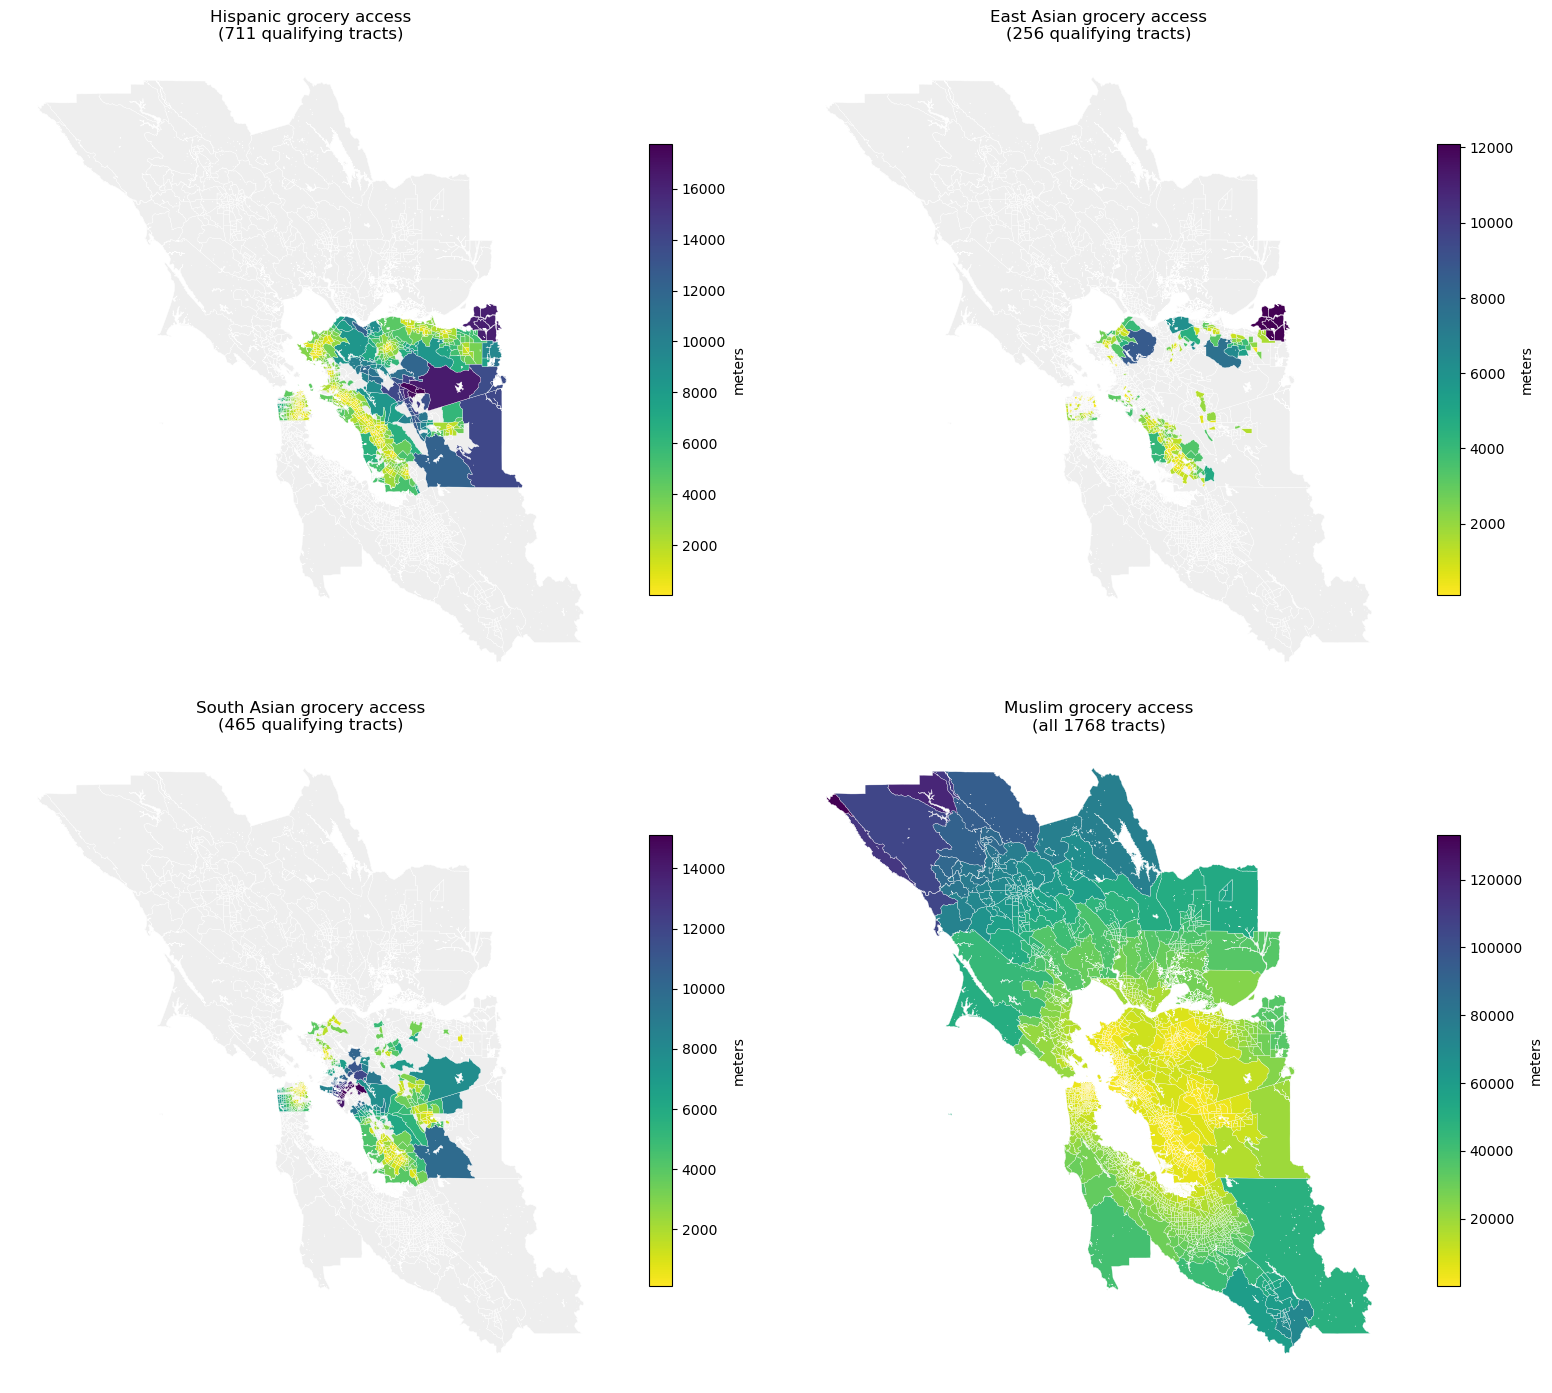

In [78]:
bay_gdf["geometry_center"] = bay_gdf.geometry.representative_point()

def tract_distance(stores_types, gdf, colname):
    tracts_crs3310 = gdf.copy().to_crs(3310)
    centers = gdf.set_geometry("geometry_center").to_crs(3310)
    tracts_crs3310 = gpd.GeoDataFrame(tracts_crs3310[["geoid"]], geometry=centers.geometry, crs=3310)
    stores_crs3310 = stores_types.to_crs(3310)
    nearest = gpd.sjoin_nearest(tracts_crs3310[["geoid", "geometry"]], stores_crs3310[["name", "geometry"]], 
                                how="left", distance_col="dist_m")
    
    return nearest.groupby("geoid")["dist_m"].min().reindex(gdf["geoid"]).rename(colname)

for flag in ["hispanic", "chinese_eastasian", "south_asian", "muslim"]:
    print(f"{flag:20s} {stores_gdf[flag].sum():4d} stores (flag on stores_gdf)" if flag in stores_gdf.columns else f"{flag:20s} MISSING")
    CULTURAL_DIST = [
    ("hispanic",          "dist_hispanic_cultural"),
    ("chinese_eastasian", "dist_east_asian_cultural"),
    ("south_asian",       "dist_south_asian_cultural"),
    ("muslim",            "dist_muslim_cultural"),
]

for store_flag, dist_col in CULTURAL_DIST:
    subset = stores_gdf[stores_gdf[store_flag]]
    dist = tract_distance(subset, bay_gdf, dist_col).reset_index()

    # Idempotent: drop before merge
    if dist_col in bay_gdf.columns:
        bay_gdf = bay_gdf.drop(columns=dist_col)

    bay_gdf = bay_gdf.merge(dist, on="geoid", how="left")

CULTURAL_MAPS = [
    ("Hispanic grocery access",
     "dist_hispanic_cultural",     "hispanic_tract"),
    ("East Asian grocery access",
     "dist_east_asian_cultural",   "east_asian_tract"),
    ("South Asian grocery access",
     "dist_south_asian_cultural",  "south_asian_tract"),
    ("Muslim grocery access",
     "dist_muslim_cultural",       None) #Need to find a better estimate method, not enough tracts so no filter
]

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()   # 2×2 -> 4-item array

for ax, (title, dist_col, flag_col) in zip(axes, CULTURAL_MAPS):
    bay_gdf.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.3)

    use_all_tracts = (
        flag_col is None
        or flag_col not in bay_gdf.columns
        or bay_gdf[flag_col].sum() == 0
    )

    if use_all_tracts:
        bay_gdf.plot(
            ax=ax, column=dist_col, cmap="viridis_r",
            legend=True, legend_kwds={"label": "meters", "shrink": 0.7},
            edgecolor="white", linewidth=0.2,
        )
        ax.set_title(f"{title}\n(all {len(bay_gdf)} tracts)", fontsize=12)
    else:
        q = bay_gdf[bay_gdf[flag_col]]
        q.plot(
            ax=ax, column=dist_col, cmap="viridis_r",
            legend=True, legend_kwds={"label": "meters", "shrink": 0.7},
            edgecolor="white", linewidth=0.2,
        )
        ax.set_title(f"{title}\n({len(q)} qualifying tracts)", fontsize=12)

    ax.set_axis_off()

plt.tight_layout()
plt.savefig("cultural_access_maps_2x2.png", dpi=150, bbox_inches="tight")
plt.show()

The above graph showcases distance (in meters) from each tract's centroid to the nearest culturally-specific grocery store.